# LeetCode #1113: Intersection of Three Sorted Arrays

https://leetcode.com/problems/intersection-of-three-sorted-arrays/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O(n_1 \cdot n_2 \cdot n_3)$ | $O(1)$ |
| **Optimal: Three Pointers ★** | $O(n_1 + n_2 + n_3)$ | $O(1)$ |

---

## Understanding the Methods

### Brute Force
For each element in arr1, binary-search (or linear-scan) arr2 and arr3. With three nested loops this is $O(n_1 \cdot n_2 \cdot n_3)$ — wasteful since the arrays are already sorted.

### Optimal: Three Pointers ★
Maintain one pointer per array. At each step, advance the pointer pointing at the smallest value. When all three pointers point at the same value, record it and advance all three.

**Why this is better than Brute Force:** Each pointer advances at most $n_i$ times, giving $O(n_1 + n_2 + n_3)$ total steps — one linear pass per array, exploiting sortedness directly.

**Constraints:**
* 1 <= arr1.length, arr2.length, arr3.length <= 1000
* 1 <= arr1[i], arr2[j], arr3[k] <= 2000
* Each array is sorted in strictly increasing order

## Solutions

### C#

In [ ]:
public class Solution {
    public IList<int> ArraysIntersection(int[] arr1, int[] arr2, int[] arr3) {
        var result = new List<int>();
        int i = 0, j = 0, k = 0;
        while (i < arr1.Length && j < arr2.Length && k < arr3.Length) {
            if (arr1[i] == arr2[j] && arr2[j] == arr3[k]) {
                // All three pointers agree — this value is in the intersection
                result.Add(arr1[i]);
                i++; j++; k++;
            } else {
                // Advance the pointer pointing at the smallest value to catch up
                int minVal = Math.Min(arr1[i], Math.Min(arr2[j], arr3[k]));
                if (arr1[i] == minVal) i++;
                if (arr2[j] == minVal) j++;
                if (arr3[k] == minVal) k++;
            }
        }
        return result;
    }
}

### Python

In [ ]:
class Solution:
    def arraysIntersection(self, arr1: list[int], arr2: list[int], arr3: list[int]) -> list[int]:
        result = []
        i = j = k = 0
        while i < len(arr1) and j < len(arr2) and k < len(arr3):
            if arr1[i] == arr2[j] == arr3[k]:
                # All three pointers agree — this value is in the intersection
                result.append(arr1[i])
                i += 1; j += 1; k += 1
            else:
                # Advance the pointer pointing at the smallest value to catch up
                min_val = min(arr1[i], arr2[j], arr3[k])
                if arr1[i] == min_val: i += 1
                if arr2[j] == min_val: j += 1
                if arr3[k] == min_val: k += 1
        return result

### Go

In [ ]:
func arraysIntersection(arr1 []int, arr2 []int, arr3 []int) []int {
    result := []int{}
    i, j, k := 0, 0, 0
    for i < len(arr1) && j < len(arr2) && k < len(arr3) {
        if arr1[i] == arr2[j] && arr2[j] == arr3[k] {
            // All three pointers agree — this value is in the intersection
            result = append(result, arr1[i])
            i++; j++; k++
        } else {
            // Advance the pointer pointing at the smallest value to catch up
            minVal := arr1[i]
            if arr2[j] < minVal { minVal = arr2[j] }
            if arr3[k] < minVal { minVal = arr3[k] }
            if arr1[i] == minVal { i++ }
            if arr2[j] == minVal { j++ }
            if arr3[k] == minVal { k++ }
        }
    }
    return result
}

### Rust

In [ ]:
impl Solution {
    pub fn arrays_intersection(arr1: Vec<i32>, arr2: Vec<i32>, arr3: Vec<i32>) -> Vec<i32> {
        let mut result = Vec::new();
        let (mut i, mut j, mut k) = (0, 0, 0);
        while i < arr1.len() && j < arr2.len() && k < arr3.len() {
            if arr1[i] == arr2[j] && arr2[j] == arr3[k] {
                // All three pointers agree — this value is in the intersection
                result.push(arr1[i]);
                i += 1; j += 1; k += 1;
            } else {
                // Advance the pointer pointing at the smallest value to catch up
                let min_val = arr1[i].min(arr2[j]).min(arr3[k]);
                if arr1[i] == min_val { i += 1; }
                if arr2[j] == min_val { j += 1; }
                if arr3[k] == min_val { k += 1; }
            }
        }
        result
    }
}

## Example Scenarios

### 1. Common Case — Two Shared Values
**Input:** `arr1 = [1,2,3,4,5]`, `arr2 = [1,2,5,7,9]`, `arr3 = [1,3,4,5,8]`

All three pointers start on 1, so 1 is recorded and every pointer advances. Then the triples are $(2,2,3) \to$ advance $i, j$; $(3,5,3) \to$ advance $i, k$; $(4,5,4) \to$ advance $i, k$; $(5,5,5) \to$ record 5. Five loop iterations, output **[1, 5]**.

### 2. Slightly Complex — Unequal Lengths, One Shared Value
**Input:** `arr1 = [1,2,3,4,5,6]`, `arr2 = [2,4,6,8]`, `arr3 = [3,6,9]`

The arrays have lengths 6, 4 and 3, and only 6 is common to all three. The loop keeps pushing whichever pointer sits on the smallest value, so `i` does most of the walking while `j` and `k` wait. Output **[6]**. The loop ends as soon as *any* array is exhausted — there is no point continuing once one of them can contribute nothing more.

### 3. Edge Case: Time Factor — Deliberately Interleaved, Nothing Shared
**Input:** `arr1 = [1,4,7,10,13]`, `arr2 = [2,5,8,11,14]`, `arr3 = [3,6,9,12,15]`

Every value is distinct, so exactly one pointer moves per iteration — the slowest possible progress. The loop runs $n_1 + n_2 + n_3 - 2 = 13$ times before `arr1` runs out, which is the theoretical maximum for these lengths. Output **[]**. At the constraint limit this is at most $3 \times 1000 - 2 = 2998$ iterations, against $10^9$ for the triple-nested brute force.

### 4. Edge Case: Space Factor — One Long Array, Two Singletons
**Input:** `arr1 = [1,2,3,4,5,6,7,8]`, `arr2 = [8]`, `arr3 = [8]`

`i` advances seven times on its own while `j` and `k` sit still, then all three agree on 8. Output **[8]** after 8 iterations. Space is the point: beyond the output list the algorithm holds only `i`, `j`, `k`, so the auxiliary cost is $O(1)$ — a hash-set intersection would instead need $O(n_1)$ for the first array's contents.

### 5. Almost-Impossible but Plausible — Three Singletons at the Value Ceiling
**Input:** `arr1 = [2000]`, `arr2 = [2000]`, `arr3 = [2000]`

The shortest legal input at the largest legal value, $arr_i[j] \le 2000$. One comparison settles it: all three agree, 2000 is recorded, all pointers step past the end, and the loop exits. Output **[2000]**. Nothing about the algorithm depends on value magnitude — only on ordering — so the ceiling is irrelevant to its cost.

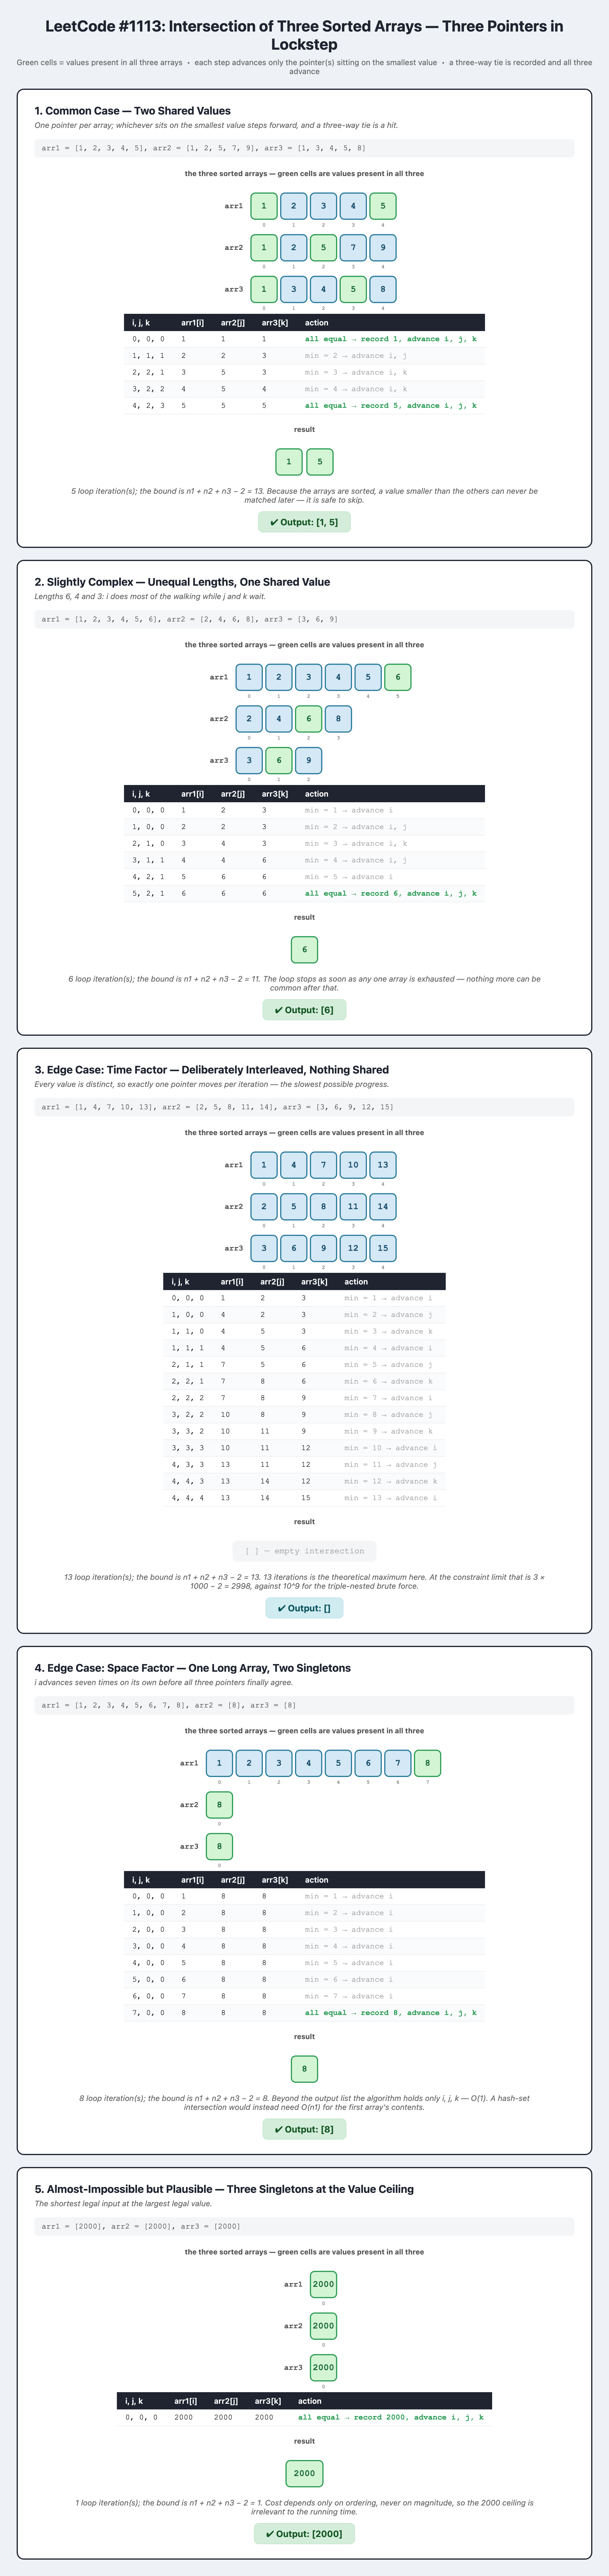